
# Week 3: Unsupervised Learning and Clustering Analysis
## Customer Segmentation Using K-Means Clustering

### Objective
To group customers according to their annual income and spending score using unsupervised learning.

### Tools and Libraries
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn

### Project Workflow
1. Dataset collection
2. Data exploration and preprocessing
3. Feature standardization
4. Finding the optimal number of clusters
5. Applying K-Means clustering
6. Visualizing and interpreting clusters
7. Preparing the final report


In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("All libraries imported successfully!")


All libraries imported successfully!


In [7]:

from pathlib import Path
import urllib.request

data_dir = Path("../data")
data_dir.mkdir(parents=True, exist_ok=True)

url = "https://raw.githubusercontent.com/ffzs/dataset/master/Mall_Customers.csv"

file_path = data_dir / "Mall_Customers.csv"

try:
    urllib.request.urlretrieve(url, file_path)
    print("Dataset downloaded successfully!")
    print("Saved at:", file_path.resolve())
except Exception as e:
    print("Download failed:", e)


Dataset downloaded successfully!
Saved at: D:\YuvaIntern_Week1_DataScience\Week3_Clustering_Analysis\data\Mall_Customers.csv


In [8]:

# Load the dataset
df = pd.read_csv(file_path)

# Display the first 5 rows
print("First 5 rows:")
display(df.head())

# Check dataset dimensions
print("\nDataset shape:", df.shape)

# Check column names
print("\nColumn names:")
print(df.columns.tolist())

# Check data types and missing values
print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())


First 5 rows:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Dataset shape: (200, 5)

Column names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [9]:

# Generate descriptive statistics
print("Statistical Summary:")
display(df.describe())

# Check unique values in categorical columns
print("\nGender distribution:")
display(df["Gender"].value_counts())

# Check for duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check unique customer IDs
print("\nUnique Customer IDs:", df["CustomerID"].nunique())


Statistical Summary:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000



Gender distribution:


Gender
Female    112
Male       88
Name: count, dtype: int64


Duplicate rows: 0

Unique Customer IDs: 200


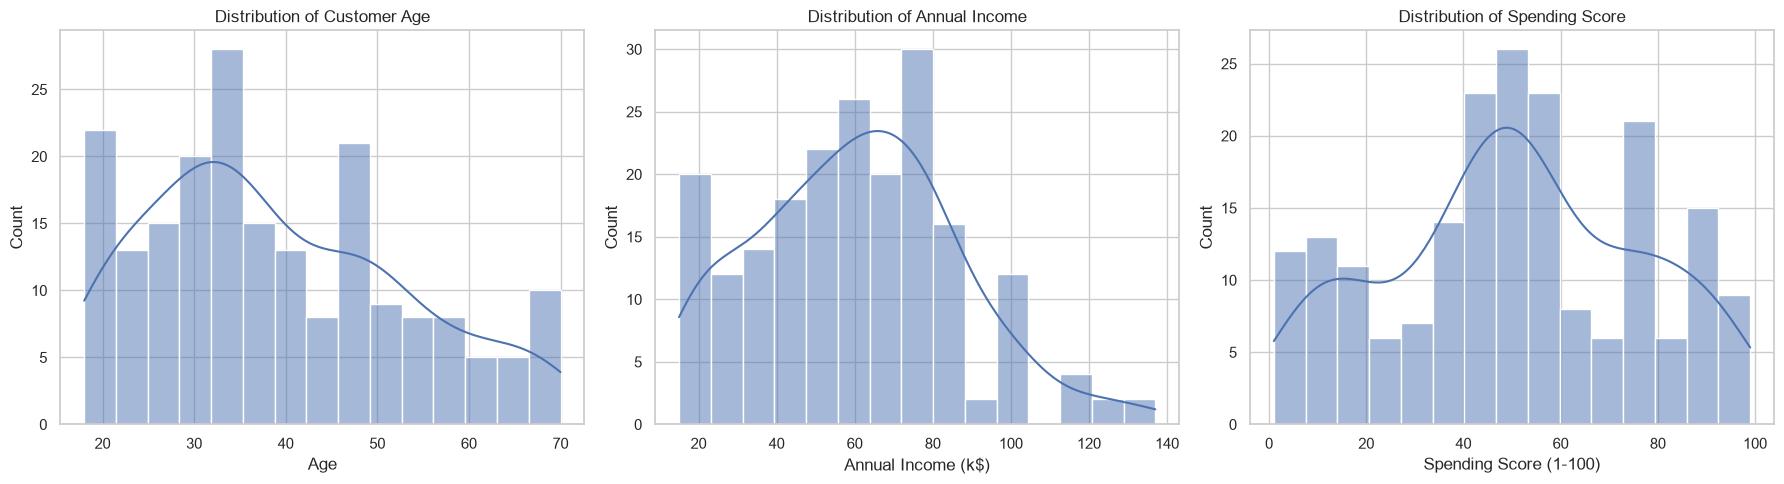

In [10]:

# Set the visual style
sns.set_theme(style="whitegrid")

# Create three distribution plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df["Age"], bins=15, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Customer Age")

sns.histplot(df["Annual Income (k$)"], bins=15, kde=True, ax=axes[1])
axes[1].set_title("Distribution of Annual Income")

sns.histplot(df["Spending Score (1-100)"], bins=15, kde=True, ax=axes[2])
axes[2].set_title("Distribution of Spending Score")

plt.tight_layout()
plt.show()


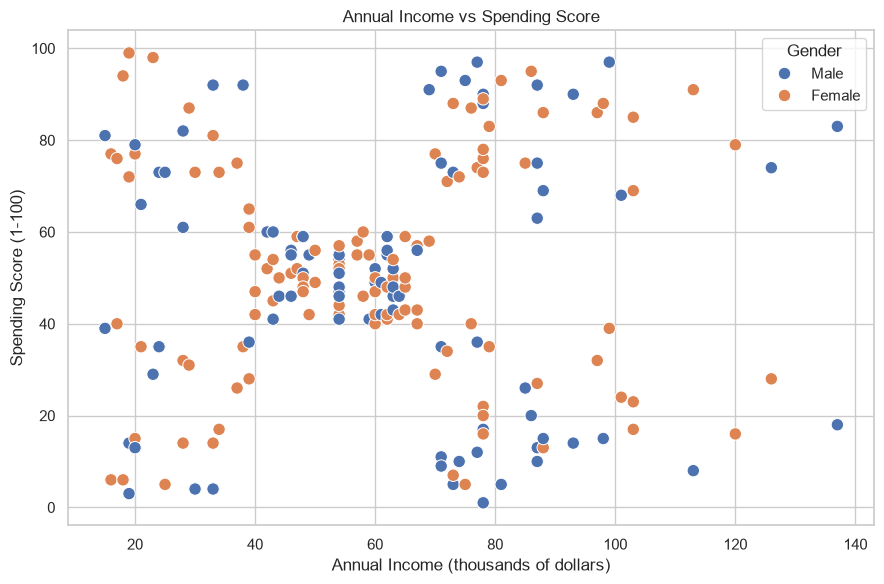

In [11]:

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Gender",
    s=80
)

plt.title("Annual Income vs Spending Score")
plt.xlabel("Annual Income (thousands of dollars)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Gender")
plt.tight_layout()
plt.show()


In [12]:

# Select the two features for customer segmentation
X = df[["Annual Income (k$)", "Spending Score (1-100)"]].copy()

print("Selected features:")
display(X.head())

print("\nFeature data shape:", X.shape)
print("\nMissing values:")
print(X.isnull().sum())


Selected features:


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40



Feature data shape: (200, 2)

Missing values:
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [13]:

# Standardize both features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Standardization completed!")
print("Scaled data shape:", X_scaled.shape)

print("\nFeature means after scaling:")
print(X_scaled.mean(axis=0).round(3))

print("\nFeature standard deviations after scaling:")
print(X_scaled.std(axis=0).round(3))


Standardization completed!
Scaled data shape: (200, 2)

Feature means after scaling:
[-0. -0.]

Feature standard deviations after scaling:
[1. 1.]


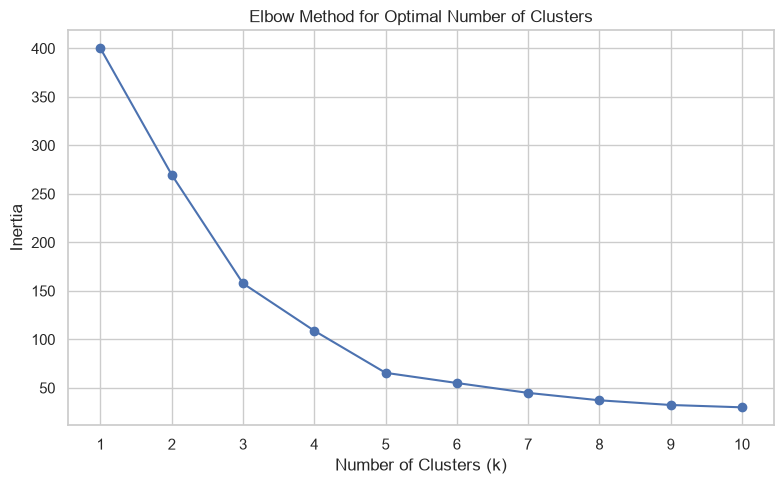

In [15]:

from threadpoolctl import threadpool_limits

inertia_values = []

with threadpool_limits(limits=1):
    for k in range(1, 11):
        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )
        model.fit(X_scaled)
        inertia_values.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia_values, marker="o")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.xticks(range(1, 11))
plt.grid(True)
plt.tight_layout()
plt.show()


k = 2: Silhouette Score = 0.3213
k = 3: Silhouette Score = 0.4666
k = 4: Silhouette Score = 0.4939
k = 5: Silhouette Score = 0.5547
k = 6: Silhouette Score = 0.5399
k = 7: Silhouette Score = 0.5281
k = 8: Silhouette Score = 0.4552
k = 9: Silhouette Score = 0.4571
k = 10: Silhouette Score = 0.4432


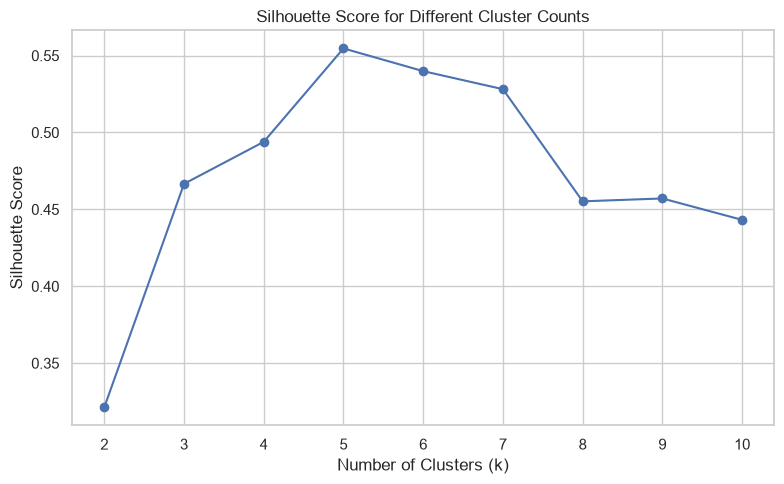

In [16]:

from threadpoolctl import threadpool_limits

silhouette_scores = []

with threadpool_limits(limits=1):
    for k in range(2, 11):
        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )
        labels = model.fit_predict(X_scaled)
        score = silhouette_score(X_scaled, labels)
        silhouette_scores.append(score)

# Display the scores
for k, score in zip(range(2, 11), silhouette_scores):
    print(f"k = {k}: Silhouette Score = {score:.4f}")

# Plot the scores
plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), silhouette_scores, marker="o")
plt.title("Silhouette Score for Different Cluster Counts")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.grid(True)
plt.tight_layout()
plt.show()


In [17]:

# Train K-Means using 5 clusters
with threadpool_limits(limits=1):
    kmeans = KMeans(
        n_clusters=5,
        random_state=42,
        n_init=10
    )

    df["Cluster"] = kmeans.fit_predict(X_scaled)

print("K-Means model trained successfully!")

print("\nNumber of customers in each cluster:")
display(df["Cluster"].value_counts().sort_index())

print("\nFirst 10 customers with cluster labels:")
display(df.head(10))


K-Means model trained successfully!

Number of customers in each cluster:


Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


First 10 customers with cluster labels:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4
5,6,Female,22,17,76,2
6,7,Female,35,18,6,4
7,8,Female,23,18,94,2
8,9,Male,64,19,3,4
9,10,Female,30,19,72,2


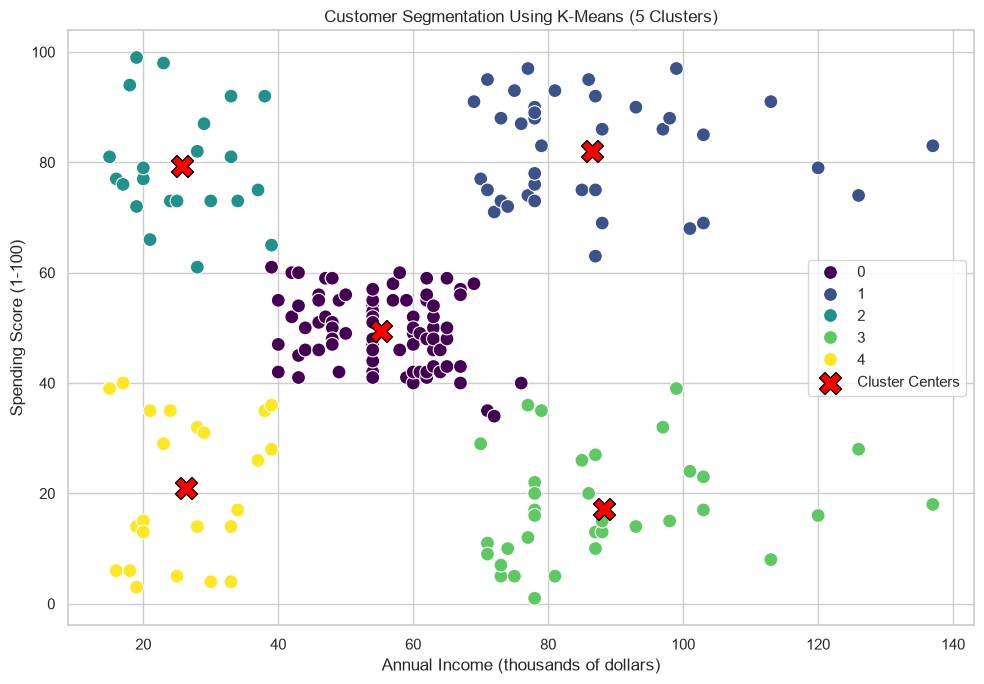

In [18]:

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="viridis",
    s=100
)

# Plot the cluster centers in the original feature scale
centers = scaler.inverse_transform(kmeans.cluster_centers_)

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker="X",
    s=250,
    color="red",
    edgecolor="black",
    label="Cluster Centers"
)

plt.title("Customer Segmentation Using K-Means (5 Clusters)")
plt.xlabel("Annual Income (thousands of dollars)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.tight_layout()
plt.show()


In [19]:

# Calculate average customer characteristics for each cluster
cluster_summary = df.groupby("Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending_Score=("Spending Score (1-100)", "mean")
).round(2)

print("Customer Cluster Analysis:")
display(cluster_summary)

# Export the summary for the final report
cluster_summary.to_csv("../data/week3_cluster_summary.csv")

print("Cluster summary saved successfully!")


Customer Cluster Analysis:


,Customer_Count,Average_Age,Average_Income,Average_Spending_Score
Cluster,,,,
0,81,42.72,55.30,49.52
1,39,32.69,86.54,82.13
2,22,25.27,25.73,79.36
3,35,41.11,88.20,17.11
4,23,45.22,26.30,20.91


Cluster summary saved successfully!


In [20]:

# Evaluate the final clustering model
with threadpool_limits(limits=1):
    final_score = silhouette_score(X_scaled, df["Cluster"])

print(f"Number of clusters: {df['Cluster'].nunique()}")
print(f"Final Silhouette Score: {final_score:.4f}")

# Save customer data with cluster assignments
output_path = "../data/week3_customers_with_clusters.csv"
df.to_csv(output_path, index=False)

print("\nClustered customer data saved to:", output_path)


Number of clusters: 5
Final Silhouette Score: 0.5547

Clustered customer data saved to: ../data/week3_customers_with_clusters.csv


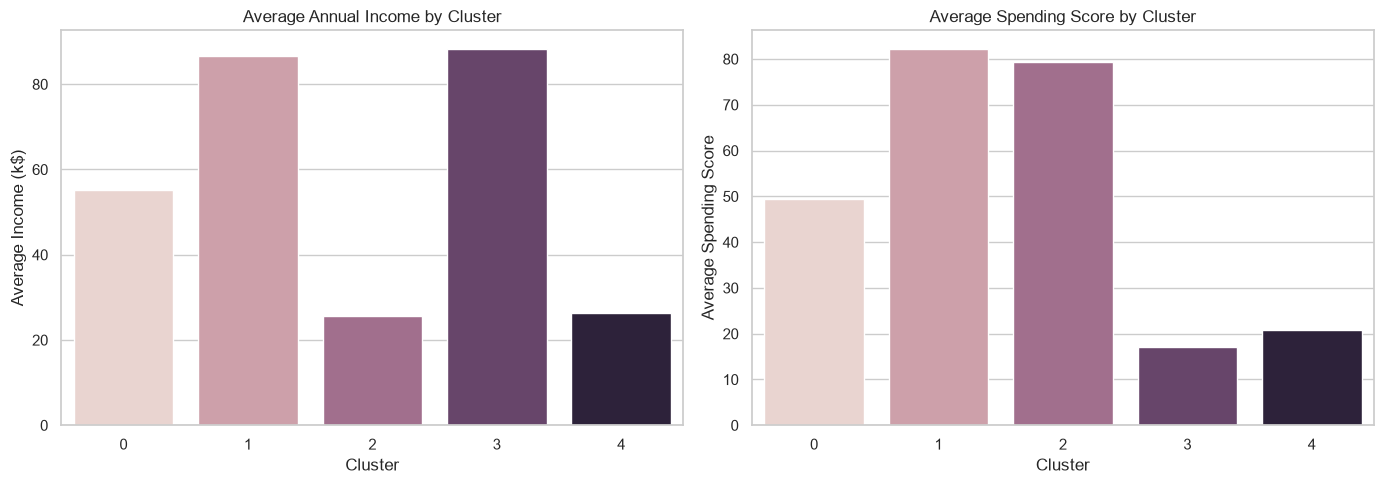

In [21]:

# Compare average income and spending across clusters
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=cluster_summary.reset_index(),
    x="Cluster",
    y="Average_Income",
    hue="Cluster",
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Average Annual Income by Cluster")
axes[0].set_xlabel("Cluster")
axes[0].set_ylabel("Average Income (k$)")

sns.barplot(
    data=cluster_summary.reset_index(),
    x="Cluster",
    y="Average_Spending_Score",
    hue="Cluster",
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Average Spending Score by Cluster")
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Average Spending Score")

plt.tight_layout()
plt.show()


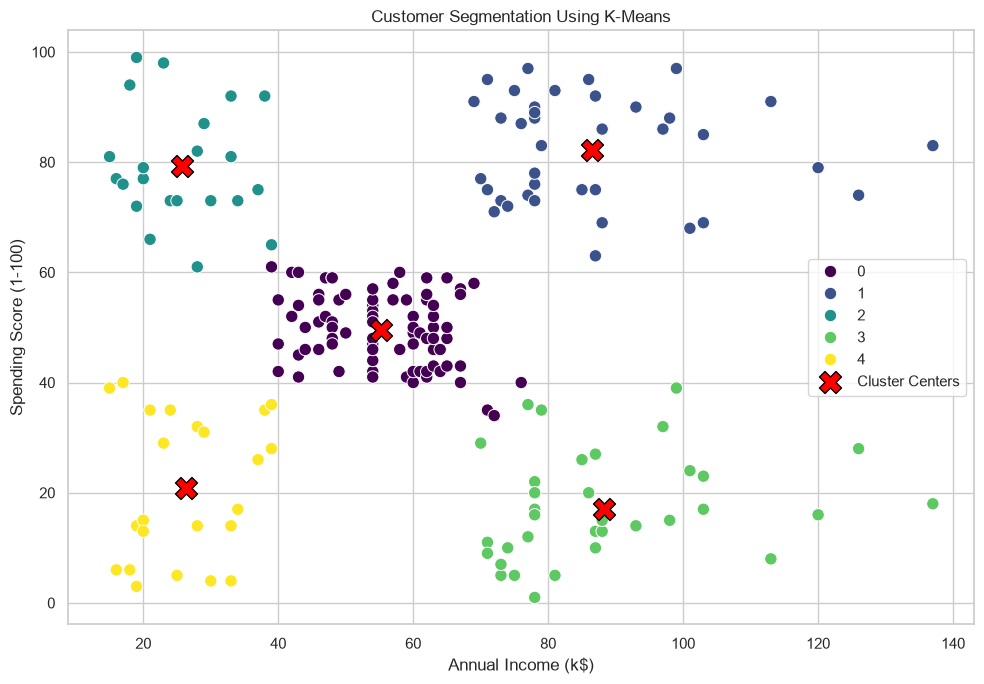

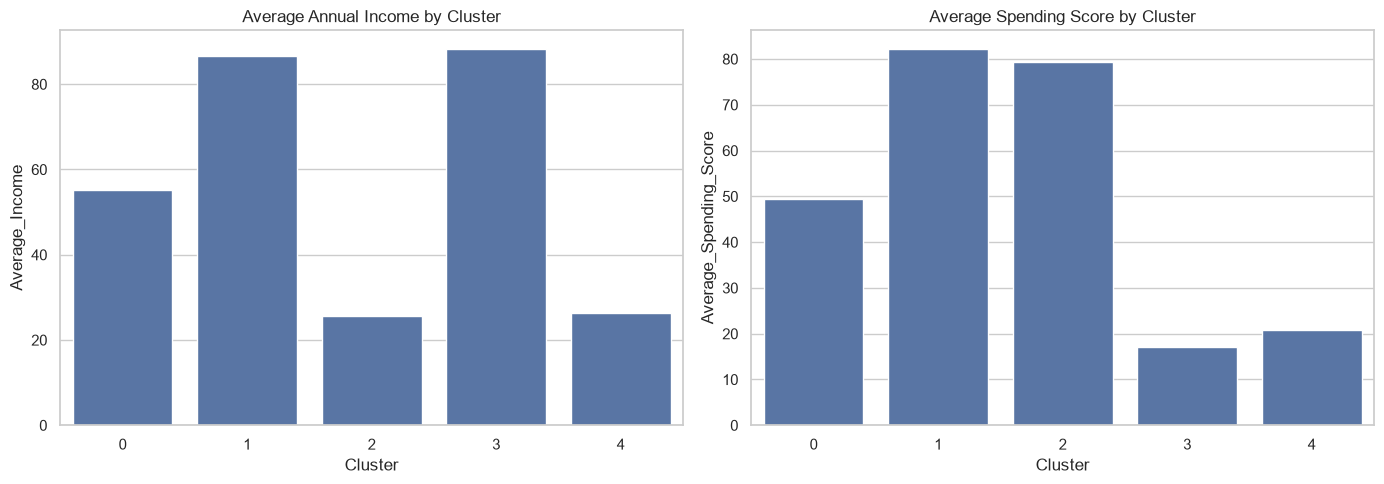

Saved visualization files:
..\screenshots\week3_customer_clusters.png
..\screenshots\week3_cluster_comparison.png
Cluster summary CSV saved.


In [22]:

from pathlib import Path

# Create a folder for Week 3 outputs
output_dir = Path("../screenshots")
output_dir.mkdir(parents=True, exist_ok=True)

# Save the customer cluster scatter plot
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="viridis",
    s=80
)

centers = scaler.inverse_transform(kmeans.cluster_centers_)
plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker="X",
    s=250,
    color="red",
    edgecolor="black",
    label="Cluster Centers"
)

plt.title("Customer Segmentation Using K-Means")
plt.legend()
plt.tight_layout()
plt.savefig(output_dir / "week3_customer_clusters.png", dpi=300, bbox_inches="tight")
plt.show()

# Save cluster comparison charts
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
summary_plot = cluster_summary.reset_index()

sns.barplot(data=summary_plot, x="Cluster", y="Average_Income", ax=axes[0])
axes[0].set_title("Average Annual Income by Cluster")

sns.barplot(data=summary_plot, x="Cluster", y="Average_Spending_Score", ax=axes[1])
axes[1].set_title("Average Spending Score by Cluster")

plt.tight_layout()
plt.savefig(output_dir / "week3_cluster_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

# Save the cluster summary
cluster_summary.to_csv("../data/week3_cluster_summary.csv")

print("Saved visualization files:")
print(output_dir / "week3_customer_clusters.png")
print(output_dir / "week3_cluster_comparison.png")
print("Cluster summary CSV saved.")


In [23]:

from pathlib import Path

# Project summary
print("=" * 50)
print("WEEK 3: CUSTOMER SEGMENTATION USING K-MEANS")
print("=" * 50)

print(f"Total customers analyzed: {len(df)}")
print(f"Features used: {list(X.columns)}")
print(f"Number of clusters: {df['Cluster'].nunique()}")
print(f"Silhouette score: {final_score:.4f}")

print("\nCluster sizes:")
display(df["Cluster"].value_counts().sort_index())

print("\nCluster characteristics:")
display(cluster_summary)

print("\nOutput files:")
for folder in ["../data", "../screenshots"]:
    folder_path = Path(folder)
    if folder_path.exists():
        for file in sorted(folder_path.iterdir()):
            if file.is_file() and file.name.startswith("week3_"):
                print("-", file.name)

print("\nProject summary completed!")


WEEK 3: CUSTOMER SEGMENTATION USING K-MEANS
Total customers analyzed: 200
Features used: ['Annual Income (k$)', 'Spending Score (1-100)']
Number of clusters: 5
Silhouette score: 0.5547

Cluster sizes:


Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


Cluster characteristics:


,Customer_Count,Average_Age,Average_Income,Average_Spending_Score
Cluster,,,,
0,81,42.72,55.30,49.52
1,39,32.69,86.54,82.13
2,22,25.27,25.73,79.36
3,35,41.11,88.20,17.11
4,23,45.22,26.30,20.91



Output files:
- week3_cluster_summary.csv
- week3_customers_with_clusters.csv
- week3_cluster_comparison.png
- week3_customer_clusters.png

Project summary completed!
